In [126]:
import pandas as pd
df= pd.read_csv("C:\\Users\\Latika\\Downloads\\Personal_Finance_Dataset.csv")


In [127]:
df.describe()
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Date                     1500 non-null   object 
 1   Transaction Description  1500 non-null   object 
 2   Category                 1500 non-null   object 
 3   Amount                   1500 non-null   float64
 4   Type                     1500 non-null   object 
dtypes: float64(1), object(4)
memory usage: 58.7+ KB


In [128]:
df["Category"].value_counts()
df["Type"].value_counts()

Type
Expense    1222
Income      278
Name: count, dtype: int64

In [129]:
df["Date"] = pd.to_datetime(df["Date"])

df["Month"] = df["Date"].dt.month


In [130]:
df["Week"] = df["Date"].dt.to_period("W")

In [131]:
df["Week"].head()

0    2019-12-30/2020-01-05
1    2019-12-30/2020-01-05
2    2019-12-30/2020-01-05
3    2019-12-30/2020-01-05
4    2020-01-13/2020-01-19
Name: Week, dtype: period[W-SUN]

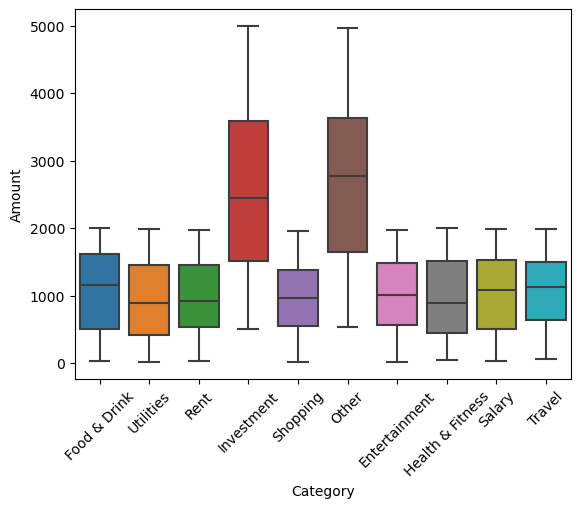

In [132]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.boxplot(data=df, x="Category", y="Amount")
plt.xticks(rotation=45)
plt.show()

In [133]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
1495    False
1496    False
1497    False
1498    False
1499    False
Length: 1500, dtype: bool

In [134]:
monthly_food = df[df["Category"] == "Food & Drink"].groupby("Month")["Amount"].sum()

In [135]:
monthly_health = df[df["Category"] == "Health & Fitness"].groupby("Month")["Amount"].sum()

In [136]:



monthly_food = monthly_food.rename("FoodAmount")
monthly_health = monthly_health.rename("HealthAmount")

merged = pd.merge(
    monthly_food,
    monthly_health,
    on="Month"
)

In [137]:
merged

,FoodAmount,HealthAmount
Month,,
1,23369.45,11866.06
2,16955.88,14672.98
3,12957.81,11252.29
4,11938.41,14540.29
5,10676.96,12968.02
6,18544.43,13423.92
7,12085.47,14829.33
8,18991.85,11059.42
9,10916.15,6102.34


In [138]:
monthly = df.pivot_table(
    values="Amount",
    index="Month",
    columns="Category",
    aggfunc=["sum","max", "count"],
    fill_value=0
)

In [139]:
print(monthly.stack().to_string())



                             sum      max  count
Month Category                                  
1     Entertainment     17641.81  1948.88     16
      Food & Drink      23369.45  1973.90     21
      Health & Fitness  11866.06  1996.26     11
      Investment        36334.00  4364.00     13
      Other             42680.00  4975.00     16
      Rent               9727.47  1794.22     10
      Salary            10734.60  1909.36      8
      Shopping          10148.87  1708.14     13
      Travel            15781.67  1756.18     15
      Utilities         13148.92  1962.86     15
2     Entertainment     13945.84  1918.20     10
      Food & Drink      16955.88  1945.39     14
      Health & Fitness  14672.98  1932.01     16
      Investment        33041.00  4883.00     11
      Other             37636.00  4009.00     15
      Rent               7732.64  1365.57      9
      Salary             7726.48  1993.30      7
      Shopping          11632.87  1934.87      9
      Travel        

C:\Users\Latika\AppData\Local\Temp\ipykernel_15668\2779022770.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  print(monthly.stack().to_string())


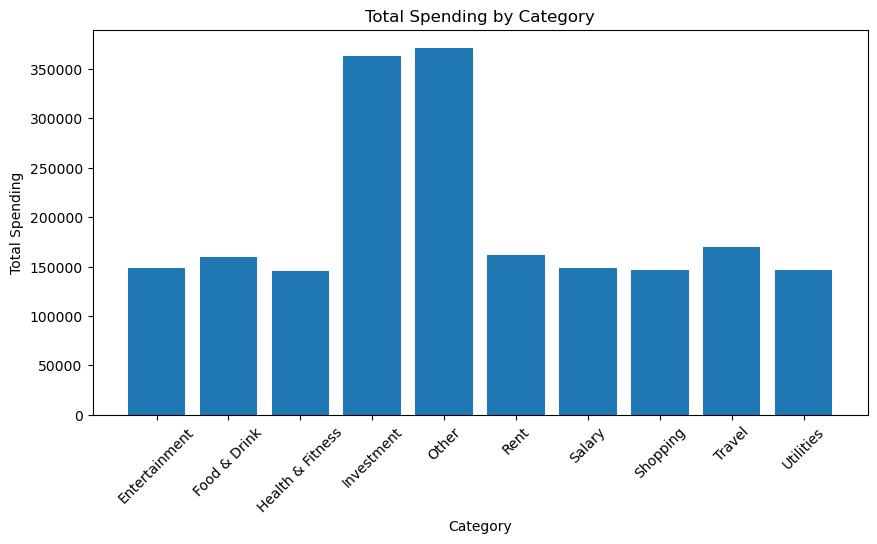

In [140]:
category_total = df.groupby("Category")["Amount"].sum()

plt.figure(figsize=(10, 5))

plt.bar(category_total.index, category_total.values)

plt.xlabel("Category")
plt.ylabel("Total Spending")
plt.title("Total Spending by Category")

plt.xticks(rotation=45)

plt.show()

In [141]:
monthly= df.groupby(["Month", "Category"])["Amount"].sum()

Text(0.5, 1.0, 'Total Spending by Month')

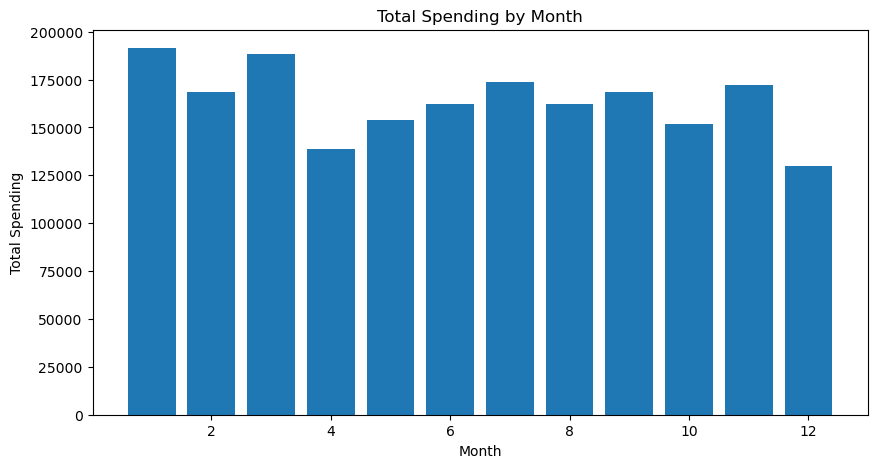

In [142]:
monthly_total = df.groupby("Month")["Amount"].sum()

plt.figure(figsize=(10, 5))

plt.bar(monthly_total.index, monthly_total.values)

plt.xlabel("Month")
plt.ylabel("Total Spending")
plt.title("Total Spending by Month")


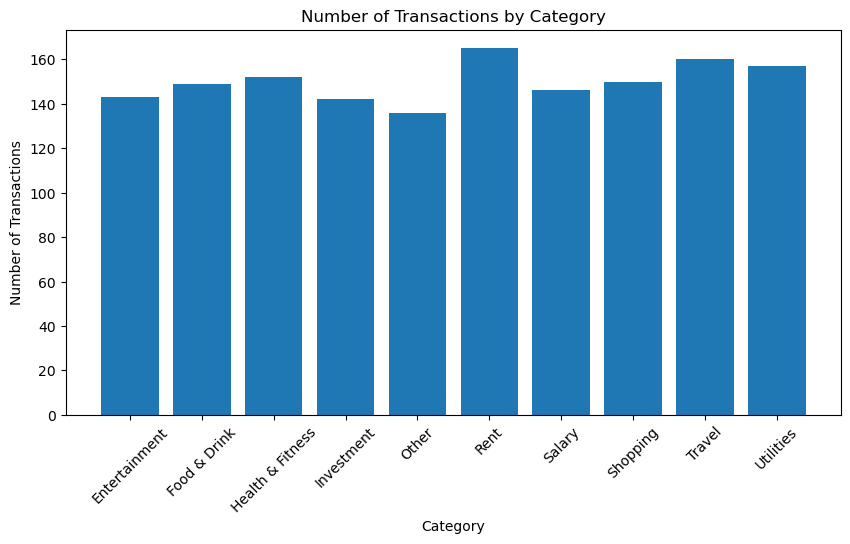

In [143]:
transaction_count = df.groupby("Category")["Amount"].count()

plt.figure(figsize=(10, 5))

plt.bar(transaction_count.index, transaction_count.values)

plt.xlabel("Category")
plt.ylabel("Number of Transactions")
plt.title("Number of Transactions by Category")

plt.xticks(rotation=45)

plt.show()

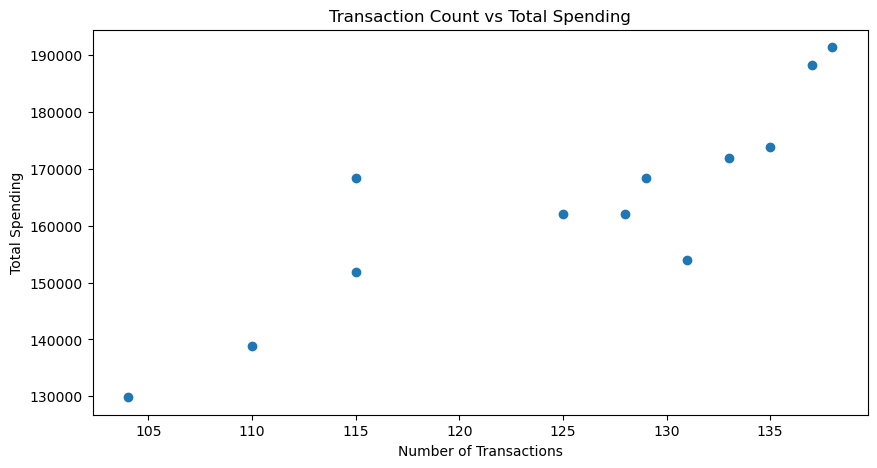

In [144]:
#number of trsnsactions vs spending
monthly_sum= df.groupby(["Month"])["Amount"].sum()
monthly_count =df.groupby(["Month"])["Amount"].count()

plt.figure(figsize=(10, 5))

plt.scatter(monthly_count, monthly_sum)

plt.xlabel("Number of Transactions")
plt.ylabel("Total Spending")
plt.title("Transaction Count vs Total Spending")

plt.show()

In [145]:
monthly_sum.corr(monthly_count)

0.8611591728667295